# EndToEndPhysicsUnrollSPECTNet: Multi-Stage Unrolling Clinical Case Inspector

This notebook provides an **end-to-end interactive workspace** to inspect the internal stage-by-stage evolution of the joint CT-less SPECT unrolling network.

### How to Use:
1. In **Cell 2**, set `PATIENT_ID` to any patient ID from the test/validation set (e.g., `'301539147'`, `'300210121'`, `'301415729'`, etc.).
2. Click **Run All** (or run cell-by-cell).
3. In seconds, the notebook loads the geometry, executes all 4 unrolled stages via the zero-copy CUDA `libnmrecon.so` physics engine, prints the quantitative evaluation table, and renders the high-resolution comparison figures!

---

In [1]:
import os
import sys
import json
from pathlib import Path

import torch
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
matplotlib.rcParams['figure.dpi'] = 140
from skimage.metrics import structural_similarity as ssim

# Ensure ctless-unroll repository is in python path
WORKSPACE = Path('/home/wengfenghua/workspace/SparseSPECT/ctless-unroll')
if str(WORKSPACE) not in sys.path:
    sys.path.insert(0, str(WORKSPACE))

from models.true_unroll_spect import EndToEndPhysicsUnrollSPECTNet
from train_true_unroll_siemens_nii import SiemensNiiFullUnrollDataset, collate_fn
from nmrecon_training_projector import projector_from_batch

print(f'PyTorch Version: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}')

PyTorch Version: 2.7.1+cu118 | CUDA Available: True


In [2]:
# =========================================================================
# 🎯 CASE CONFIGURATION: CHANGE THIS TO ANY CASE YOU WANT TO INSPECT!
# =========================================================================
PATIENT_ID = '301539147'  # Default: Strictly monotonic Stage 0 -> 4 progression
SPLIT_TYPE = 'test'       # 'test' (25 cases), 'val' (25 cases), or 'train' (185 cases)
DEVICE = os.environ.get('CUDA_DEVICE', 'cuda:0' if torch.cuda.is_available() else 'cpu')
CKPT_PATH = str(WORKSPACE / 'checkpoints_v1_backup/checkpoint_best_48.61dB.pt')

# Load test split to display available candidate IDs for copy-paste
split_file = WORKSPACE / f'splits_siemens_nii/siemens_nii_{SPLIT_TYPE}.json'
with open(split_file) as f:
    available_cases = [c['patient_id'] for c in json.load(f)['cases']]

print(f'Selected Target Patient ID: {PATIENT_ID} on {DEVICE}')
print(f'Total {SPLIT_TYPE} cases available ({len(available_cases)}):')
print(', '.join(available_cases[:12]) + ', ...')

Selected Target Patient ID: 301539147 on cuda:0
Total test cases available (25):
301513349, 611486782, 301539147, 301415729, 300295201, 300210121, 001258172, 000281264, 000355074, 301291228, 301529564, 001233888, ...


In [3]:
cache_dir = WORKSPACE / 'data/cache_siemens_nii'
dataset = SiemensNiiFullUnrollDataset(str(split_file), str(cache_dir))

# Find selected case
matching_indices = [i for i, c in enumerate(dataset.valid_cases) if c['patient_id'] == PATIENT_ID]
if not matching_indices:
    raise ValueError(f'Patient ID {PATIENT_ID} not found in {SPLIT_TYPE} split! Available: {available_cases[:5]}...')

case_idx = matching_indices[0]
batch = collate_fn([dataset[case_idx]])

# Build native zero-copy Distance-Driven projector via NMRecon
projector = projector_from_batch(batch, DEVICE)

print(f'Successfully loaded case {PATIENT_ID} (Index {case_idx})!')
print(f'Primary projection views: {batch["proj_primary"].shape[1]} | Matrix: {tuple(batch["x_gt"].shape[2:])}')

Loaded 25 / 25 ready cached Siemens cases from /home/wengfenghua/workspace/SparseSPECT/ctless-unroll/splits_siemens_nii/siemens_nii_test.json


[DEBUG nmrecon_create] called with path=/home/wengfenghua/workspace/SparseSPECT/data/Siemens/nii/301539147/recon.json device=0


Successfully loaded case 301539147 (Index 2)!
Primary projection views: 64 | Matrix: (128, 128, 128)


In [4]:
print(f'Loading model from checkpoint: {CKPT_PATH}...')
ckpt = torch.load(CKPT_PATH, map_location='cpu', weights_only=False)

model = EndToEndPhysicsUnrollSPECTNet(
    num_stages=4, base_ch=16, cond_dim=4, share_weights=True, net_depth=4
).to(DEVICE)
model.load_state_dict(ckpt['model'])
model.eval()

print('Executing 4-stage physics-unrolled forward pass...')
with torch.no_grad():
    out = model(
        lam_init_p=batch['lam_init_p'].to(DEVICE),
        lam_init_s=batch['lam_init_s'].to(DEVICE),
        proj_primary=batch['proj_primary'].to(DEVICE),
        scatter_est=batch['scatter_est'].to(DEVICE),
        projector_factory=projector,
        cond=batch['cond'].to(DEVICE),
        x_init_nac=batch['x_init_nac'].to(DEVICE),
        use_checkpoint=False,
        compute_projection_loss=False
    )

print(f'Forward unrolling finished! Extracted {len(out["activity_history"])} activity and {len(out["mu_history"])} mu stages.')

Loading model from checkpoint: /home/wengfenghua/workspace/SparseSPECT/ctless-unroll/checkpoints_v1_backup/checkpoint_best_48.61dB.pt...


Executing 4-stage physics-unrolled forward pass...


Forward unrolling finished! Extracted 5 activity and 5 mu stages.


In [5]:
mask = (batch['support_mask'][0, 0] > 0.5).cpu().numpy()
x_nac = batch['x_init_nac'][0, 0].cpu().numpy()
x_gt = batch['x_gt'][0, 0].cpu().numpy()
mu_gt = batch['mu_gt'][0, 0].cpu().numpy()

x_hist = [x[0, 0].cpu().numpy() for x in out['activity_history']]
mu_hist = [m[0, 0].cpu().numpy() for m in out['mu_history']]

max_x = float(np.max(x_gt[mask]))
vol_dr_x = float(np.ptp(x_gt[mask]))

bone_mask = (mu_gt > 0.175) & mask
soft_mask = (mu_gt >= 0.12) & (mu_gt <= 0.175) & mask
lung_mask = (mu_gt > 0.02) & (mu_gt < 0.12) & mask

metrics = []
# NAC Baseline
mse_nac = float(np.mean((x_nac[mask] - x_gt[mask])**2))
psnr_nac = float(10 * np.log10(max_x**2 / max(mse_nac, 1e-10)))
ssim_slices_nac = []
for z in range(x_nac.shape[0]):
    if mask[z].sum() > 20:
        _, smap = ssim(x_nac[z], x_gt[z], data_range=vol_dr_x, full=True)
        ssim_slices_nac.append(float(smap[mask[z]].mean()))
ssim_nac = float(np.mean(ssim_slices_nac)) if ssim_slices_nac else 0.0
metrics.append({
    'stage': 'NAC (Raw Unattenuated)',
    'act_psnr': round(psnr_nac, 2),
    'act_ssim': round(ssim_nac, 4),
    'mu_psnr': float('nan'),
    'bone_mae': float('nan'),
    'soft_mae': float('nan')
})

for k in range(len(x_hist)):
    xk = x_hist[k]
    muk = mu_hist[k]
    
    mse_x = float(np.mean((xk[mask] - x_gt[mask])**2))
    psnr_x = float(10 * np.log10(max_x**2 / max(mse_x, 1e-10)))
    
    # 3D global dynamic range SSIM across axial slices
    ssim_slices = []
    for z in range(xk.shape[0]):
        if mask[z].sum() > 20:
            _, smap = ssim(xk[z], x_gt[z], data_range=vol_dr_x, full=True)
            ssim_slices.append(float(smap[mask[z]].mean()))
    ssim_x = float(np.mean(ssim_slices)) if ssim_slices else 0.0
    
    mse_mu = float(np.mean((muk[mask] - mu_gt[mask])**2))
    psnr_mu = float(10 * np.log10(0.25**2 / max(mse_mu, 1e-10)))
    b_mae = float(np.mean(np.abs(muk[bone_mask] - mu_gt[bone_mask]))) if bone_mask.any() else float('nan')
    s_mae = float(np.mean(np.abs(muk[soft_mask] - mu_gt[soft_mask]))) if soft_mask.any() else float('nan')
    
    lbl = 'Stage 0 (Chang Initial)' if k == 0 else f'Stage {k}'
    metrics.append({
        'stage': lbl,
        'act_psnr': round(psnr_x, 2),
        'act_ssim': round(ssim_x, 4),
        'mu_psnr': round(psnr_mu, 2),
        'bone_mae': round(b_mae, 4),
        'soft_mae': round(s_mae, 4)
    })

# Print formatted table
header = f"{'Stage':<24} | {'Act PSNR (dB)':<14} | {'Act SSIM':<10} | {'Mu PSNR (dB)':<13} | {'Bone MAE':<10} | {'Soft MAE':<10}"
print('=' * len(header))
print(f'   STAGE-BY-STAGE EVALUATION METRICS FOR PATIENT: {PATIENT_ID}')
print('=' * len(header))
print(header)
print('-' * len(header))
for m in metrics:
    print(f"{m['stage']:<24} | {str(m['act_psnr']):<14} | {str(m['act_ssim']):<10} | {str(m['mu_psnr']):<13} | {str(m['bone_mae']):<10} | {str(m['soft_mae']):<10}")
print('=' * len(header))

   STAGE-BY-STAGE EVALUATION METRICS FOR PATIENT: 301539147
Stage                    | Act PSNR (dB)  | Act SSIM   | Mu PSNR (dB)  | Bone MAE   | Soft MAE  
------------------------------------------------------------------------------------------------
NAC (Raw Unattenuated)   | 32.49          | 0.9327     | nan           | nan        | nan       
Stage 0 (Chang Initial)  | 34.69          | 0.9752     | 21.19         | 0.0272     | 0.0222    
Stage 1                  | 37.1           | 0.9819     | 21.19         | 0.027      | 0.0221    
Stage 2                  | 39.75          | 0.9866     | 21.19         | 0.0268     | 0.0221    
Stage 3                  | 42.17          | 0.9891     | 21.18         | 0.0265     | 0.022     
Stage 4                  | 43.07          | 0.9891     | 21.18         | 0.0263     | 0.022     


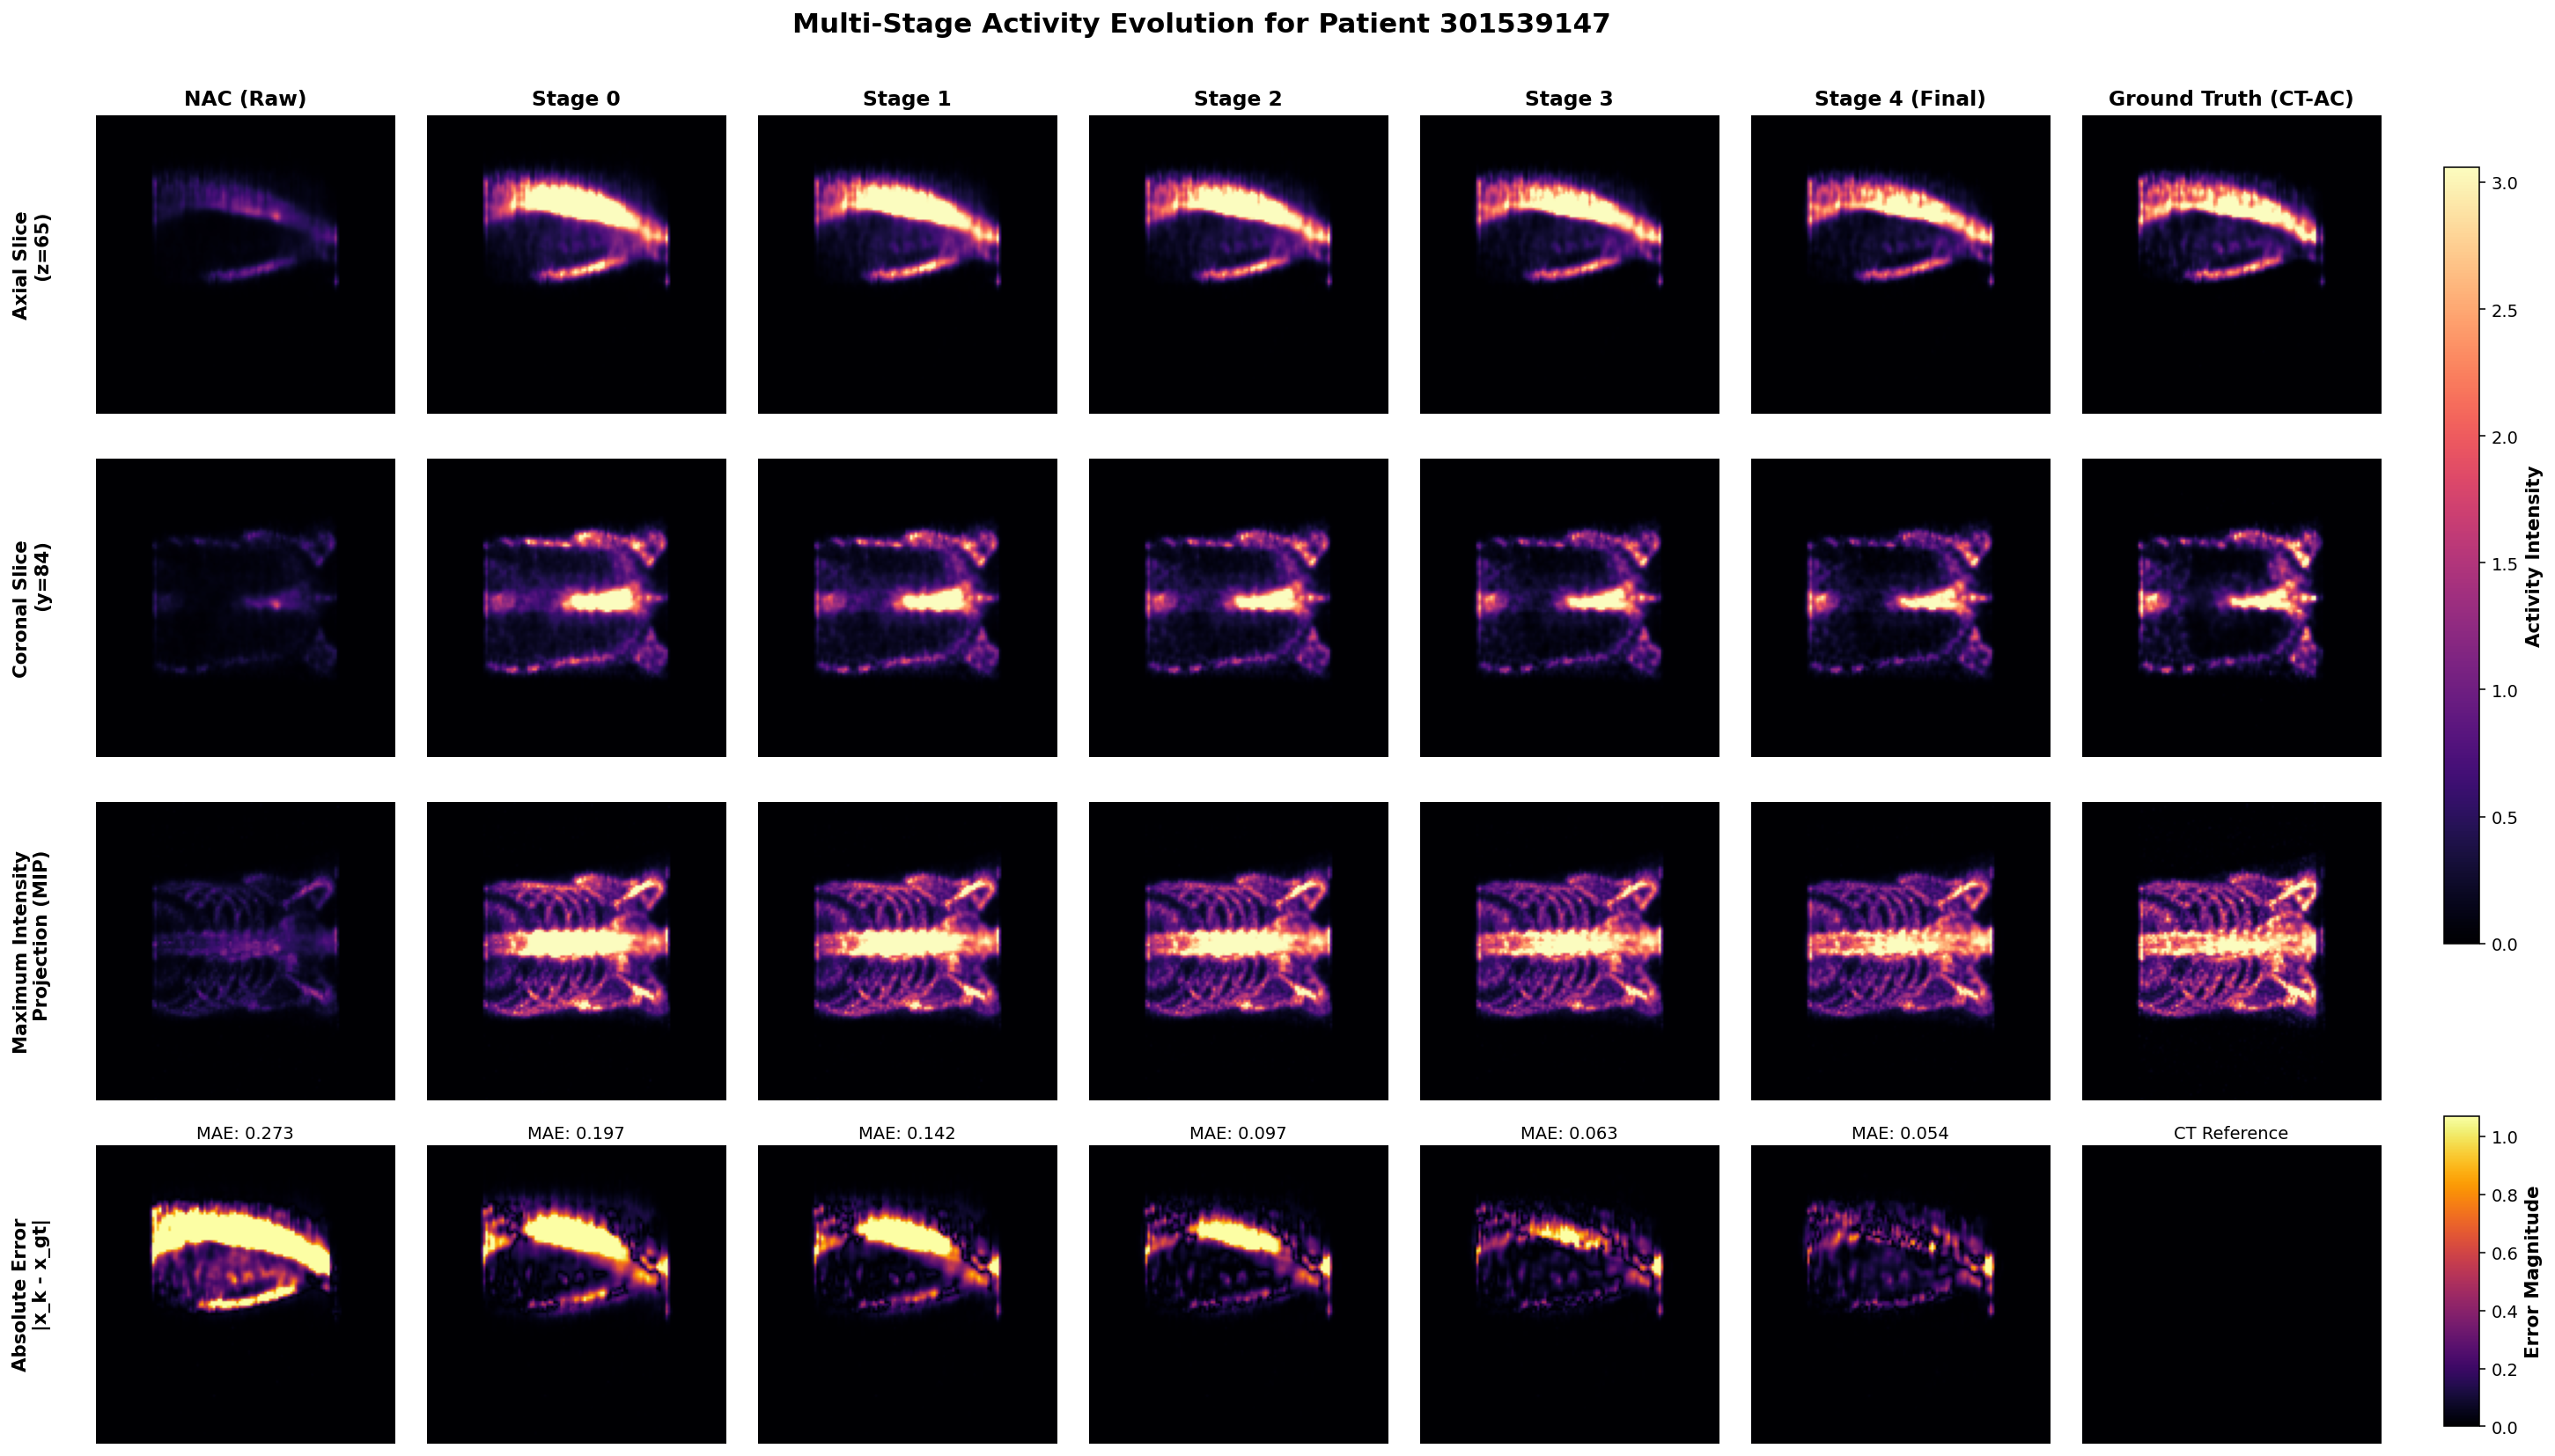

In [6]:
# Identify slice with peak lesion/vertebral uptake
z_lesion = int(np.argmax(np.max(x_gt, axis=(1, 2))))
y_lesion = int(np.argmax(np.max(x_gt, axis=(0, 2))))

stages_x = [x_nac] + x_hist + [x_gt]
titles_x = ['NAC (Raw)', 'Stage 0', 'Stage 1', 'Stage 2', 'Stage 3', 'Stage 4 (Final)', 'Ground Truth (CT-AC)']

vmax_act = float(np.percentile(x_gt[mask], 99.8))
vmax_err = vmax_act * 0.35

fig, axes = plt.subplots(4, 7, figsize=(24, 14), dpi=140)
plt.subplots_adjust(wspace=0.08, hspace=0.15)

for col, (vol, title) in enumerate(zip(stages_x, titles_x)):
    # Row 0: Axial
    ax0 = axes[0, col]
    im0 = ax0.imshow(vol[z_lesion], cmap='magma', vmin=0, vmax=vmax_act, origin='lower')
    ax0.set_title(title, fontsize=12, fontweight='bold', pad=6)
    ax0.axis('off')
    if col == 0:
        ax0.text(-0.15, 0.5, f'Axial Slice\n(z={z_lesion})', va='center', ha='right', transform=ax0.transAxes, fontsize=11, fontweight='bold', rotation=90)
        
    # Row 1: Coronal
    ax1 = axes[1, col]
    im1 = ax1.imshow(vol[:, y_lesion, :], cmap='magma', vmin=0, vmax=vmax_act, origin='lower')
    ax1.axis('off')
    if col == 0:
        ax1.text(-0.15, 0.5, f'Coronal Slice\n(y={y_lesion})', va='center', ha='right', transform=ax1.transAxes, fontsize=11, fontweight='bold', rotation=90)
        
    # Row 2: MIP
    ax2 = axes[2, col]
    im2 = ax2.imshow(np.max(vol, axis=1), cmap='magma', vmin=0, vmax=vmax_act * 1.3, origin='lower')
    ax2.axis('off')
    if col == 0:
        ax2.text(-0.15, 0.5, 'Maximum Intensity\nProjection (MIP)', va='center', ha='right', transform=ax2.transAxes, fontsize=11, fontweight='bold', rotation=90)
        
    # Row 3: Error map
    ax3 = axes[3, col]
    if col < 6:
        err = np.abs(vol[z_lesion] - x_gt[z_lesion])
        im3 = ax3.imshow(err, cmap='inferno', vmin=0, vmax=vmax_err, origin='lower')
        mae_val = np.mean(err[mask[z_lesion]]) if mask[z_lesion].any() else 0
        ax3.set_title(f'MAE: {mae_val:.3f}', fontsize=10, pad=4)
    else:
        ax3.imshow(np.zeros_like(x_gt[z_lesion]), cmap='inferno', vmin=0, vmax=vmax_err, origin='lower')
        ax3.set_title('CT Reference', fontsize=10, pad=4)
    ax3.axis('off')
    if col == 0:
        ax3.text(-0.15, 0.5, 'Absolute Error\n|x_k - x_gt|', va='center', ha='right', transform=ax3.transAxes, fontsize=11, fontweight='bold', rotation=90)

# Colorbars
cbar_ax1 = fig.add_axes([0.92, 0.40, 0.012, 0.45])
cb1 = fig.colorbar(im0, cax=cbar_ax1)
cb1.set_label('Activity Intensity', fontsize=11, fontweight='bold')

cbar_ax2 = fig.add_axes([0.92, 0.12, 0.012, 0.18])
cb2 = fig.colorbar(im3, cax=cbar_ax2)
cb2.set_label('Error Magnitude', fontsize=11, fontweight='bold')
plt.suptitle(f'Multi-Stage Activity Evolution for Patient {PATIENT_ID}', fontsize=16, fontweight='bold', y=0.94)
fig_dir = WORKSPACE / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / f'Figure1_activity_{PATIENT_ID}.png', bbox_inches='tight', dpi=140)
plt.show()

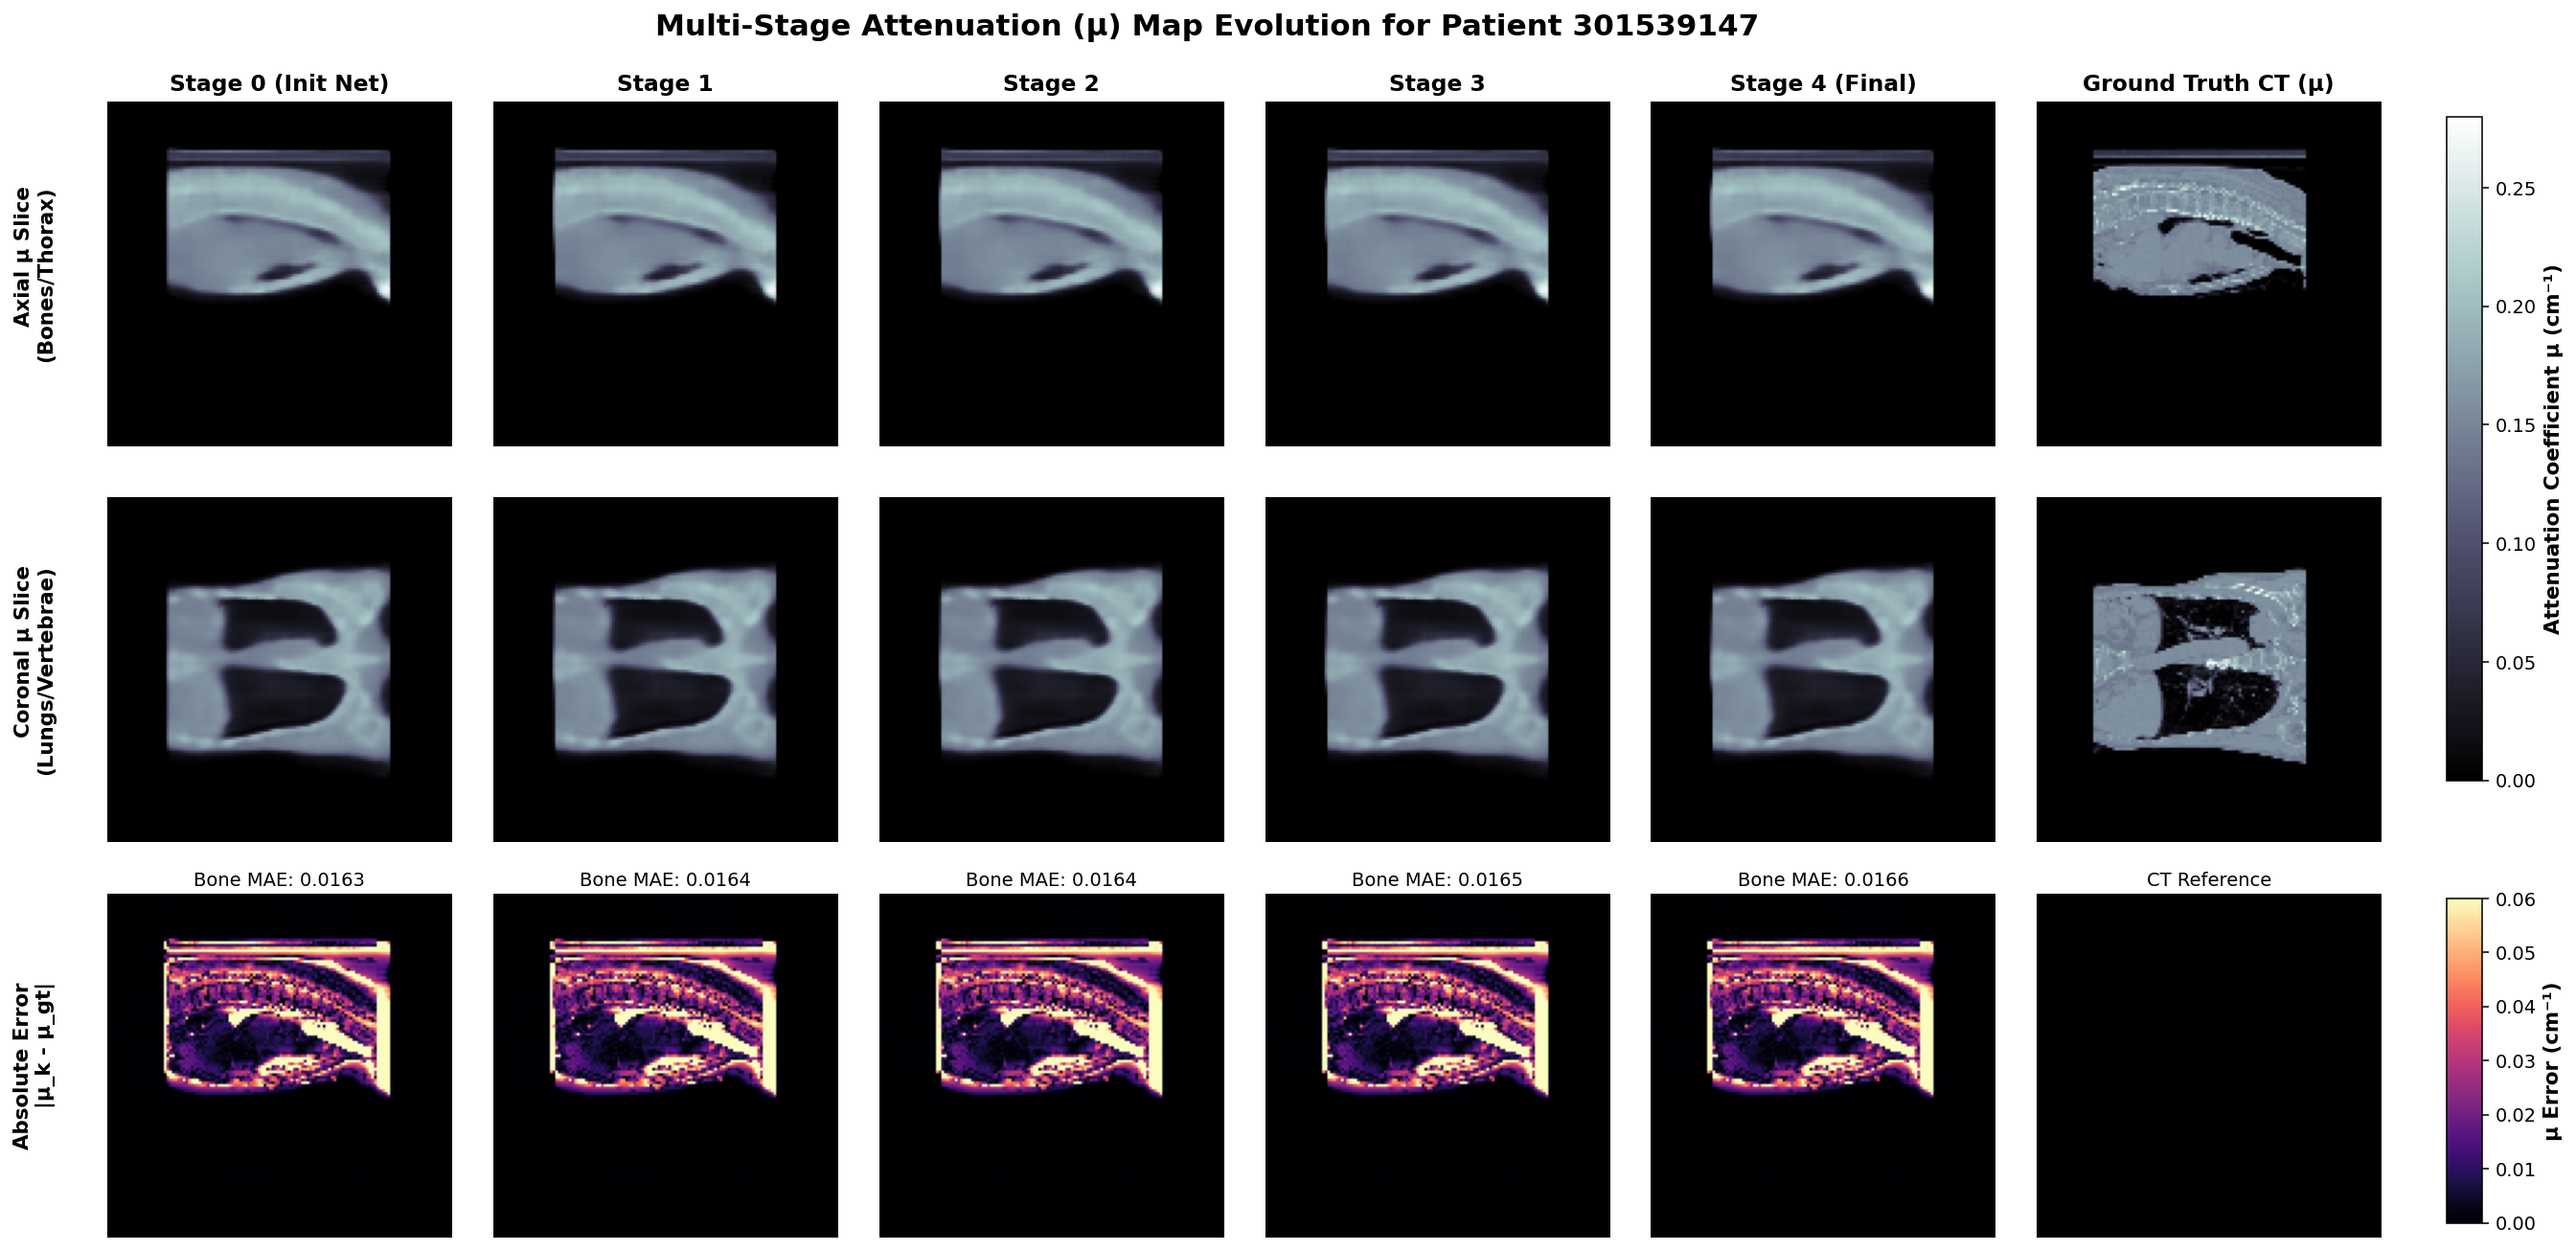

In [7]:
stages_mu = mu_hist + [mu_gt]
titles_mu = ['Stage 0 (Init Net)', 'Stage 1', 'Stage 2', 'Stage 3', 'Stage 4 (Final)', 'Ground Truth CT (μ)']
vmax_mu = 0.28
vmax_mu_err = 0.06

fig2, axes2 = plt.subplots(3, 6, figsize=(22, 11), dpi=140)
plt.subplots_adjust(wspace=0.08, hspace=0.15)

for col, (vol, title) in enumerate(zip(stages_mu, titles_mu)):
    # Row 0: Axial
    ax0 = axes2[0, col]
    im0 = ax0.imshow(vol[z_lesion], cmap='bone', vmin=0, vmax=vmax_mu, origin='lower')
    ax0.set_title(title, fontsize=12, fontweight='bold', pad=6)
    ax0.axis('off')
    if col == 0:
        ax0.text(-0.15, 0.5, 'Axial μ Slice\n(Bones/Thorax)', va='center', ha='right', transform=ax0.transAxes, fontsize=11, fontweight='bold', rotation=90)
        
    # Row 1: Coronal
    ax1 = axes2[1, col]
    im1 = ax1.imshow(vol[:, y_lesion, :], cmap='bone', vmin=0, vmax=vmax_mu, origin='lower')
    ax1.axis('off')
    if col == 0:
        ax1.text(-0.15, 0.5, 'Coronal μ Slice\n(Lungs/Vertebrae)', va='center', ha='right', transform=ax1.transAxes, fontsize=11, fontweight='bold', rotation=90)
        
    # Row 2: Error map
    ax2 = axes2[2, col]
    if col < 5:
        err = np.abs(vol[z_lesion] - mu_gt[z_lesion])
        im2 = ax2.imshow(err, cmap='magma', vmin=0, vmax=vmax_mu_err, origin='lower')
        b_err = np.mean(err[bone_mask[z_lesion]]) if bone_mask[z_lesion].any() else 0
        ax2.set_title(f'Bone MAE: {b_err:.4f}', fontsize=10, pad=4)
    else:
        ax2.imshow(np.zeros_like(mu_gt[z_lesion]), cmap='magma', vmin=0, vmax=vmax_mu_err, origin='lower')
        ax2.set_title('CT Reference', fontsize=10, pad=4)
    ax2.axis('off')
    if col == 0:
        ax2.text(-0.15, 0.5, 'Absolute Error\n|μ_k - μ_gt|', va='center', ha='right', transform=ax2.transAxes, fontsize=11, fontweight='bold', rotation=90)

cbar_ax_mu = fig2.add_axes([0.92, 0.42, 0.012, 0.45])
cb_mu = fig2.colorbar(im0, cax=cbar_ax_mu)
cb_mu.set_label('Attenuation Coefficient μ (cm⁻¹)', fontsize=11, fontweight='bold')

cbar_ax_mu_err = fig2.add_axes([0.92, 0.12, 0.012, 0.22])
cb_mu_err = fig2.colorbar(im2, cax=cbar_ax_mu_err)
cb_mu_err.set_label('μ Error (cm⁻¹)', fontsize=11, fontweight='bold')
plt.suptitle(f'Multi-Stage Attenuation (μ) Map Evolution for Patient {PATIENT_ID}', fontsize=16, fontweight='bold', y=0.94)
fig2.savefig(fig_dir / f'Figure2_attenuation_{PATIENT_ID}.png', bbox_inches='tight', dpi=140)
plt.show()

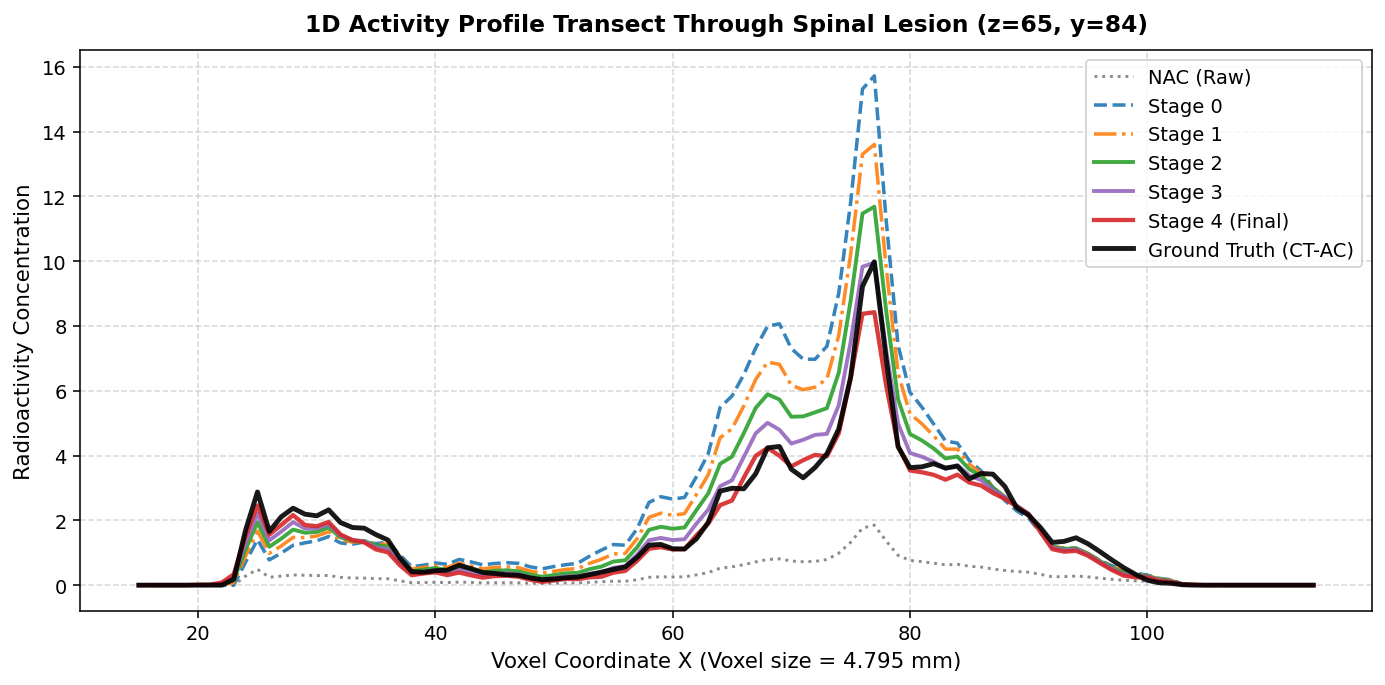

In [8]:
# Profile passing through maximum lesion/spinal count
x_prof_line = int(np.argmax(x_gt[z_lesion]))
y_line_idx = x_prof_line // x_gt.shape[2]
x_line = slice(15, 115)
voxels = np.arange(15, 115)

colors = ['#7f7f7f', '#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#d62728', '#000000']
linestyles = [':', '--', '-.', '-', '-', '-', '-']
linewidths = [1.5, 1.8, 1.8, 2.0, 2.0, 2.2, 2.5]

plt.figure(figsize=(10, 5), dpi=140)
for vol, title, c, ls, lw in zip(stages_x, titles_x, colors, linestyles, linewidths):
    profile = vol[z_lesion, y_line_idx, x_line]
    plt.plot(voxels, profile, label=title, color=c, linestyle=ls, linewidth=lw, alpha=0.9)

plt.title(f'1D Activity Profile Transect Through Spinal Lesion (z={z_lesion}, y={y_line_idx})', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Voxel Coordinate X (Voxel size = 4.795 mm)', fontsize=11)
plt.ylabel('Radioactivity Concentration', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10, loc='upper right')
plt.tight_layout()
plt.savefig(fig_dir / f'Figure3_line_profile_{PATIENT_ID}.png', bbox_inches='tight', dpi=140)
plt.show()

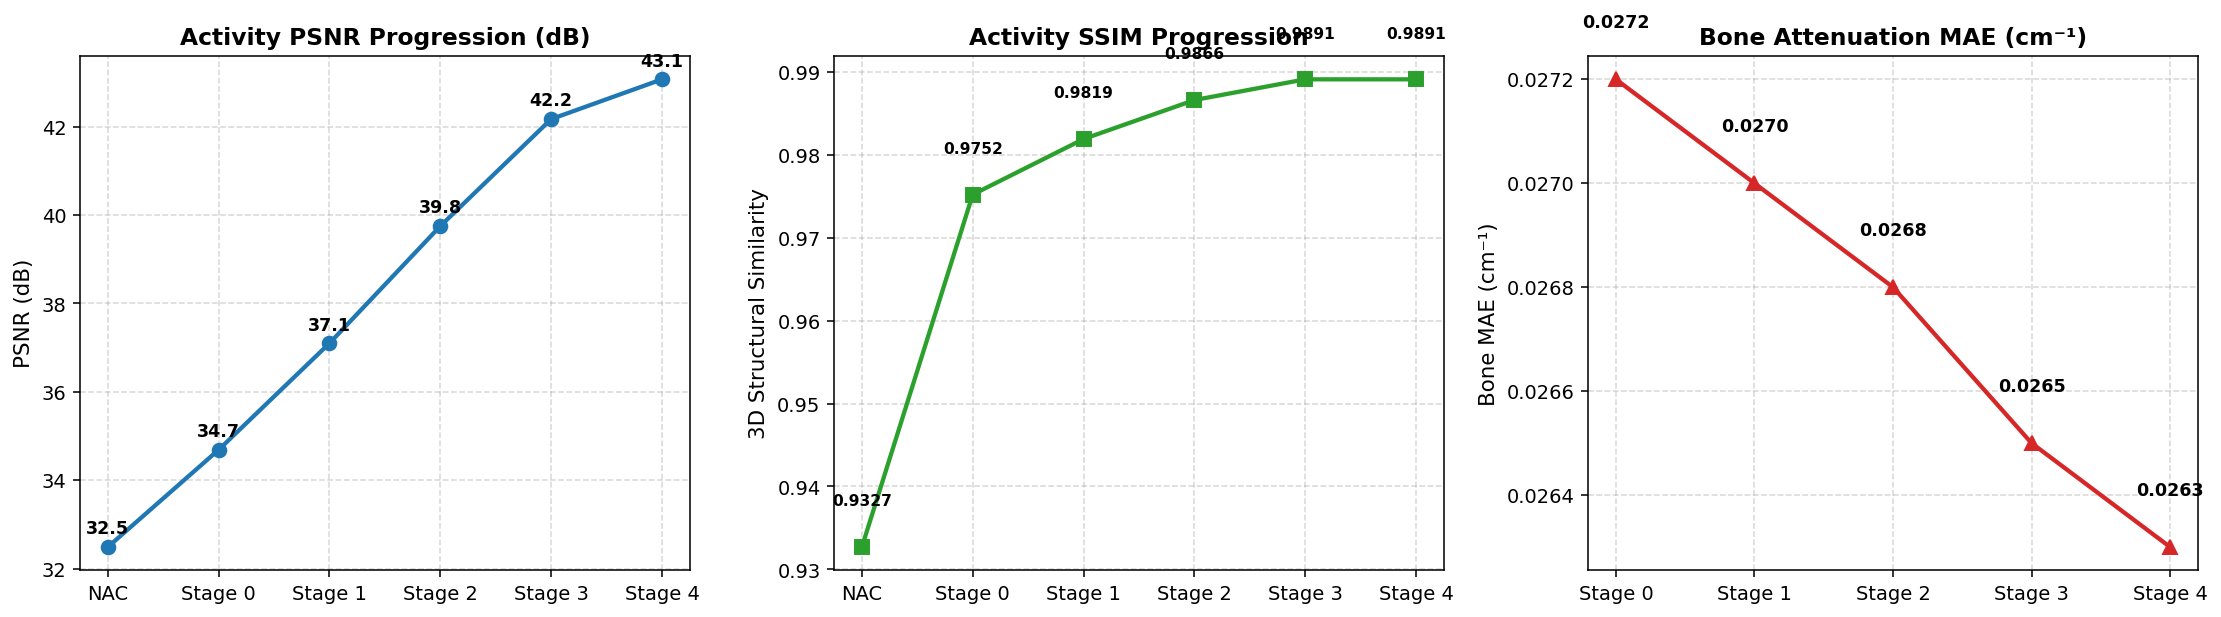

In [9]:
stage_labels = ['NAC', 'Stage 0', 'Stage 1', 'Stage 2', 'Stage 3', 'Stage 4']
act_psnrs = [m['act_psnr'] for m in metrics]
act_ssims = [m['act_ssim'] for m in metrics]
bone_maes = [m['bone_mae'] for m in metrics[1:]]

fig4, (ax4a, ax4b, ax4c) = plt.subplots(1, 3, figsize=(16, 4.5), dpi=140)

ax4a.plot(stage_labels, act_psnrs, marker='o', color='#1f77b4', linewidth=2.2, markersize=7)
ax4a.set_title('Activity PSNR Progression (dB)', fontsize=12, fontweight='bold')
ax4a.set_ylabel('PSNR (dB)', fontsize=11)
ax4a.grid(True, linestyle='--', alpha=0.5)
for i, v in enumerate(act_psnrs):
    ax4a.text(i, v + 0.3, f'{v:.1f}', ha='center', fontsize=9, fontweight='bold')

ax4b.plot(stage_labels, act_ssims, marker='s', color='#2ca02c', linewidth=2.2, markersize=7)
ax4b.set_title('Activity SSIM Progression', fontsize=12, fontweight='bold')
ax4b.set_ylabel('3D Structural Similarity', fontsize=11)
ax4b.grid(True, linestyle='--', alpha=0.5)
for i, v in enumerate(act_ssims):
    ax4b.text(i, v + 0.005, f'{v:.4f}', ha='center', fontsize=8, fontweight='bold')

ax4c.plot(stage_labels[1:], bone_maes, marker='^', color='#d62728', linewidth=2.2, markersize=7)
ax4c.set_title('Bone Attenuation MAE (cm⁻¹)', fontsize=12, fontweight='bold')
ax4c.set_ylabel('Bone MAE (cm⁻¹)', fontsize=11)
ax4c.grid(True, linestyle='--', alpha=0.5)
for i, v in enumerate(bone_maes):
    ax4c.text(i, v + 0.0001, f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
fig4.savefig(fig_dir / f'Figure4_convergence_{PATIENT_ID}.png', bbox_inches='tight', dpi=140)
plt.show()

In [10]:
def browse_slices(z=z_lesion):
    fig, axes = plt.subplots(1, 7, figsize=(22, 3.5), dpi=120)
    for ax, vol, title in zip(axes, stages_x, titles_x):
        ax.imshow(vol[z], cmap='magma', vmin=0, vmax=vmax_act, origin='lower')
        ax.set_title(title, fontsize=10, fontweight='bold')
        ax.axis('off')
    plt.suptitle(f'Axial Cross-Section at z = {z}', fontsize=13, fontweight='bold')
    plt.show()

try:
    import ipywidgets as widgets
    # Drag the slider to inspect any axial slice across all stages in real-time!
    widgets.interact(browse_slices, z=widgets.IntSlider(min=0, max=127, step=1, value=z_lesion))
except Exception as e:
    print(f'Note: Interactive slider disabled in batch export mode ({e}). Showing lesion slice:')
    browse_slices(z=z_lesion)


interactive(children=(IntSlider(value=65, description='z', max=127), Output()), _dom_classes=('widget-interact…